# FinMark Data Preprocessing
This notebook contains preprocessing steps for Customer Segments, Transactions, and Social Media datasets.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"

In [9]:
segments = pd.read_csv("customer_demographics_contaminated.csv")
transactions = pd.read_csv("customer_transactions_contaminated.csv")
social = pd.read_csv("social_media_interactions_contaminated.csv")

In [10]:
print("Segments shape:", segments.shape)
print(segments.head())

print("\nTransactions shape:", transactions.shape)
print(transactions.head())

print("\nSocial shape:", social.shape)
print(social.head())

Segments shape: (3200, 6)
                             CustomerID   Age  Gender           Location  \
0  9207fa75-5758-48d1-94ad-19c041e0520f  51.0  Female         Jensenberg   
1  5fb09cd8-a473-46f7-80bd-6e49cf509078   NaN  Female       Castilloport   
2  c139496e-cc89-498a-bd90-1fb4627b6cff  37.0    Male  Lake Jennifertown   
3  50118139-7264-428f-81cc-a25fddc5d6dd  44.0    Male          Port Carl   
4  7d1f2bbc-8d16-4fbc-9b37-ece3324e8ed4  50.0  Female          Jessebury   

  IncomeLevel  SignupDate  
0         Low  2022-11-17  
1        High  2020-07-21  
2         NaN  2021-01-01  
3      Medium  2024-06-10  
4        High  2023-08-24  

Transactions shape: (3200, 6)
                             CustomerID                         TransactionID  \
0  60567026-f719-4cd6-849e-137e86d8938f  5ff75116-0a50-4d04-80fb-31e5ccbb0769   
1  4090ba85-b111-4f75-a792-c777965f5255  2c39b9fe-ff57-4d39-9321-9f5cdf187aa1   
2  9223891b-73ff-4d5c-b8ae-13ece82ee28b  f79588dd-3db9-4ffa-97f8-7de0e64259

In [11]:
segments.info()
transactions.info()
social.info()

<class 'pandas.DataFrame'>
RangeIndex: 3200 entries, 0 to 3199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   CustomerID   3200 non-null   str  
 1   Age          2909 non-null   str  
 2   Gender       3200 non-null   str  
 3   Location     3200 non-null   str  
 4   IncomeLevel  2897 non-null   str  
 5   SignupDate   3200 non-null   str  
dtypes: str(6)
memory usage: 150.1 KB
<class 'pandas.DataFrame'>
RangeIndex: 3200 entries, 0 to 3199
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   CustomerID       3200 non-null   str  
 1   TransactionID    3200 non-null   str  
 2   TransactionDate  3200 non-null   str  
 3   Amount           2896 non-null   str  
 4   ProductCategory  2901 non-null   str  
 5   PaymentMethod    3200 non-null   str  
dtypes: str(6)
memory usage: 150.1 KB
<class 'pandas.DataFrame'>
RangeIndex: 3200 entries, 0 to 3199

In [13]:
print("Segments duplicate rows:", segments.duplicated().sum())
print("Transactions duplicate rows:", transactions.duplicated().sum())
print("Social duplicate rows:", social.duplicated().sum())

print("\nSegments duplicate CustomerID:", segments['CustomerID'].duplicated().sum())
print("Transactions duplicate TransactionID:", transactions['TransactionID'].duplicated().sum())
print("Social duplicate InteractionID:", social['InteractionID'].duplicated().sum())

print("\nSegments missing:\n", segments.isnull().sum())
print("\nTransactions missing:\n", transactions.isnull().sum())
print("\nSocial missing:\n", social.isnull().sum())

Segments duplicate rows: 177
Transactions duplicate rows: 185
Social duplicate rows: 180

Segments duplicate CustomerID: 200
Transactions duplicate TransactionID: 200
Social duplicate InteractionID: 200

Segments missing:
 CustomerID       0
Age            291
Gender           0
Location         0
IncomeLevel    303
SignupDate       0
dtype: int64

Transactions missing:
 CustomerID           0
TransactionID        0
TransactionDate      0
Amount             304
ProductCategory    299
PaymentMethod        0
dtype: int64

Social missing:
 CustomerID           0
InteractionID        0
InteractionDate      0
Platform           311
InteractionType      0
Sentiment          329
dtype: int64


In [14]:
# dtypes alone don't reveal contamination hiding inside object/string columns, so inspect values directly
age_numeric = pd.to_numeric(segments['Age'], errors='coerce')
print("Age = 'Unknown':", (segments['Age'] == 'Unknown').sum())
print("Age out-of-range (<=0 or >100):", ((age_numeric <= 0) | (age_numeric > 100)).sum())
print("IncomeLevel categories:", segments['IncomeLevel'].unique())

amount_numeric = pd.to_numeric(transactions['Amount'], errors='coerce')
print("\nAmount non-numeric values:", transactions.loc[amount_numeric.isnull() & transactions['Amount'].notnull(), 'Amount'].unique())
print("Amount negative values:", (amount_numeric < 0).sum())
print("ProductCategory categories:", transactions['ProductCategory'].unique())

print("\nPlatform categories:", social['Platform'].unique())
print("Sentiment categories:", social['Sentiment'].unique())

# Dates fail to parse with a single format when the column mixes YYYY-MM-DD and DD/MM/YYYY
print("\nUnparseable TransactionDate (ISO-only parse):", pd.to_datetime(transactions['TransactionDate'], format='%Y-%m-%d', errors='coerce').isnull().sum())
print("Unparseable InteractionDate (ISO-only parse):", pd.to_datetime(social['InteractionDate'], format='%Y-%m-%d', errors='coerce').isnull().sum())
print("Unparseable SignupDate (ISO-only parse):", pd.to_datetime(segments['SignupDate'], format='%Y-%m-%d', errors='coerce').isnull().sum())

Age = 'Unknown': 34
Age out-of-range (<=0 or >100): 63
IncomeLevel categories: <StringArray>
['Low', 'High', nan, 'Medium']
Length: 4, dtype: str

Amount non-numeric values: <StringArray>
['Free']
Length: 1, dtype: str
Amount negative values: 40
ProductCategory categories: <StringArray>
[       'Clothing', 'Health & Beauty',      'Automotive',   'Home & Garden',
               nan,     'Electronics']
Length: 6, dtype: str

Platform categories: <StringArray>
[nan, 'Twitter', 'Instagram', 'Facebook']
Length: 4, dtype: str
Sentiment categories: <StringArray>
[nan, 'Neutral', 'Positive', 'Negative', 'Very Negative', 'Very Positive']
Length: 6, dtype: str

Unparseable TransactionDate (ISO-only parse): 98
Unparseable InteractionDate (ISO-only parse): 100
Unparseable SignupDate (ISO-only parse): 98


In [15]:
# Helper: SignupDate/TransactionDate/InteractionDate mix YYYY-MM-DD and DD/MM/YYYY strings
def parse_mixed_dates(series):
    iso = pd.to_datetime(series, format='%Y-%m-%d', errors='coerce')
    dmy = pd.to_datetime(series, format='%d/%m/%Y', errors='coerce')
    return iso.fillna(dmy)

In [16]:
# --- Clean Segments: dedupe (row + business key), fix Age, handle missing categories, parse dates ---
segments = segments.drop_duplicates()
segments = segments.drop_duplicates(subset='CustomerID', keep='first')

segments['Age'] = segments['Age'].replace('Unknown', np.nan)
segments['Age'] = pd.to_numeric(segments['Age'], errors='coerce')
segments.loc[(segments['Age'] <= 0) | (segments['Age'] > 100), 'Age'] = np.nan
segments['Age'] = segments['Age'].fillna(segments['Age'].median())

segments['Gender'] = segments['Gender'].str.strip()
# Missing IncomeLevel is ~10% of rows; keep the rows and flag as its own category instead of dropping them
segments['IncomeLevel'] = segments['IncomeLevel'].fillna('Unknown')

segments['SignupDate'] = parse_mixed_dates(segments['SignupDate'])
segments['CustomerID'] = segments['CustomerID'].astype(str).str.strip()

In [17]:
# --- Clean Transactions: dedupe (row + business key), fix Amount, handle missing categories, parse dates ---
transactions = transactions.drop_duplicates()
transactions = transactions.drop_duplicates(subset='TransactionID', keep='first')

transactions['Amount'] = transactions['Amount'].replace('Free', 0)
transactions['Amount'] = pd.to_numeric(transactions['Amount'], errors='coerce')
transactions.loc[transactions['Amount'] < 0, 'Amount'] = np.nan
# Median is more robust than mean here since a handful of contaminated values skew the distribution
transactions['Amount'] = transactions['Amount'].fillna(transactions['Amount'].median())

transactions['ProductCategory'] = transactions['ProductCategory'].fillna('Unknown')
transactions['PaymentMethod'] = transactions['PaymentMethod'].str.strip()

transactions['TransactionDate'] = parse_mixed_dates(transactions['TransactionDate'])
transactions['CustomerID'] = transactions['CustomerID'].astype(str).str.strip()
transactions['TransactionID'] = transactions['TransactionID'].astype(str).str.strip()

In [18]:
# --- Clean Social: dedupe (row + business key), handle missing categories, parse dates ---
social = social.drop_duplicates()
social = social.drop_duplicates(subset='InteractionID', keep='first')

social['Platform'] = social['Platform'].fillna('Unknown')
social['Sentiment'] = social['Sentiment'].fillna('Unknown')
social['InteractionType'] = social['InteractionType'].str.strip()

social['InteractionDate'] = parse_mixed_dates(social['InteractionDate'])
social['CustomerID'] = social['CustomerID'].astype(str).str.strip()
social['InteractionID'] = social['InteractionID'].astype(str).str.strip()

In [19]:
# --- Post-cleaning verification: confirm dedupe/missing-value/dtype fixes took effect ---
print("Duplicate rows -> Segments:", segments.duplicated().sum(), "Transactions:", transactions.duplicated().sum(), "Social:", social.duplicated().sum())
print("Duplicate IDs -> CustomerID:", segments['CustomerID'].duplicated().sum(),
      "TransactionID:", transactions['TransactionID'].duplicated().sum(),
      "InteractionID:", social['InteractionID'].duplicated().sum())

print("\nSegments missing:\n", segments.isnull().sum())
print("\nTransactions missing:\n", transactions.isnull().sum())
print("\nSocial missing:\n", social.isnull().sum())

segments.info()
transactions.info()
social.info()

Duplicate rows -> Segments: 0 Transactions: 0 Social: 0
Duplicate IDs -> CustomerID: 0 TransactionID: 0 InteractionID: 0

Segments missing:
 CustomerID     0
Age            0
Gender         0
Location       0
IncomeLevel    0
SignupDate     0
dtype: int64

Transactions missing:
 CustomerID         0
TransactionID      0
TransactionDate    0
Amount             0
ProductCategory    0
PaymentMethod      0
dtype: int64

Social missing:
 CustomerID         0
InteractionID      0
InteractionDate    0
Platform           0
InteractionType    0
Sentiment          0
dtype: int64
<class 'pandas.DataFrame'>
Index: 3000 entries, 0 to 2999
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   CustomerID   3000 non-null   str           
 1   Age          3000 non-null   float64       
 2   Gender       3000 non-null   str           
 3   Location     3000 non-null   str           
 4   IncomeLevel  3000 non-null   str   

In [20]:
segments.to_csv("Cleaned_Customer_Demographics.csv", index=False)
transactions.to_csv("Cleaned_Customer_Transactions.csv", index=False)
social.to_csv("Cleaned_Social_Media_Interactions.csv", index=False)

print("Saved: Cleaned_Customer_Demographics.csv, Cleaned_Customer_Transactions.csv, Cleaned_Social_Media_Interactions.csv")

Saved: Cleaned_Customer_Demographics.csv, Cleaned_Customer_Transactions.csv, Cleaned_Social_Media_Interactions.csv


## Preprocessing Summary

**Steps performed**
- Removed exact duplicate rows, then removed remaining duplicates by business key (`CustomerID`, `TransactionID`, `InteractionID`) since some duplicate records were not byte-identical.
- Converted placeholder contamination (`"Unknown"` in `Age`, `"Free"` in `Amount`) to proper missing/numeric values before imputing.
- Treated impossible values as missing: `Age` <= 0 or > 100, `Amount` < 0.
- Imputed missing numeric fields (`Age`, `Amount`) with the **median**, which is robust to the outliers/contamination present.
- Filled missing categorical fields (`IncomeLevel`, `ProductCategory`, `Platform`, `Sentiment`) with `"Unknown"` instead of dropping rows, since missingness affected ~10% of records.
- Standardized text columns by stripping stray whitespace.
- Parsed dates that mixed `YYYY-MM-DD` and `DD/MM/YYYY` formats into a single consistent `datetime64` type.
- Cast ID columns to string for consistent joins/merges downstream.

**Challenges encountered**
- Each date column mixed two different formats, so a single-format parse silently produced ~100 missing dates per column.
- `Age` and `Amount` were stored as text because of embedded placeholder strings (`"Unknown"`, `"Free"`), blocking direct numeric conversion.
- Duplicate-ID counts were higher than duplicate full-row counts, meaning some "duplicate" records had slightly different values under the same ID.

**Decisions made**
- Categorical missing values -> `"Unknown"` category (preserves rows) vs. numeric missing values -> median (robust to skew/outliers).
- Deduplicate on the business key rather than relying on full-row equality, to catch near-duplicate records sharing the same ID.

**Observed patterns**
- Missingness in `IncomeLevel`, `Platform`, and `Sentiment` is concentrated around ~10% of rows, suggesting systematic non-response rather than random noise.
- Outlier ages (`-1`, `150`) and non-numeric amounts (`"Free"`) appear to be intentionally injected contamination for this exercise.

# Extended Numerical Analysis and Data Visualization
This section uses the cleaned datasets to extend the exploratory analysis with NumPy statistics and publication-ready Matplotlib/Seaborn visualizations.

In [21]:
# Reload the exported cleaned data so this section can be run independently
segments_eda = pd.read_csv(
    "Cleaned_Customer_Demographics.csv",
    dtype={"CustomerID": "string"},
    parse_dates=["SignupDate"],
)
transactions_eda = pd.read_csv(
    "Cleaned_Customer_Transactions.csv",
    dtype={"CustomerID": "string", "TransactionID": "string"},
    parse_dates=["TransactionDate"],
)
social_eda = pd.read_csv(
    "Cleaned_Social_Media_Interactions.csv",
    dtype={"CustomerID": "string", "InteractionID": "string"},
    parse_dates=["InteractionDate"],
)

dataset_overview = pd.DataFrame({
    "Rows": [len(segments_eda), len(transactions_eda), len(social_eda)],
    "Columns": [segments_eda.shape[1], transactions_eda.shape[1], social_eda.shape[1]],
    "Missing Values": [segments_eda.isna().sum().sum(), transactions_eda.isna().sum().sum(), social_eda.isna().sum().sum()],
}, index=["Customer Demographics", "Transactions", "Social Interactions"])

display(dataset_overview)

,Rows,Columns,Missing Values
Customer Demographics,3000,6,0
Transactions,3000,6,0
Social Interactions,3000,6,0


## NumPy Statistical Summary
The table below goes beyond basic descriptive output by calculating sample variance, interquartile range (IQR), range, and coefficient of variation in addition to mean, median, standard deviation, minimum, and maximum.

In [22]:
def numpy_statistics(values):
    values = np.asarray(values, dtype=float)
    q1, q3 = np.percentile(values, [25, 75])
    mean = np.mean(values)
    return {
        "Mean": mean,
        "Median": np.median(values),
        "Std. Dev.": np.std(values, ddof=1),
        "Variance": np.var(values, ddof=1),
        "Minimum": np.min(values),
        "Maximum": np.max(values),
        "Range": np.ptp(values),
        "IQR": q3 - q1,
        "Coefficient of Variation (%)": np.std(values, ddof=1) / mean * 100,
    }

numerical_summary = pd.DataFrame({
    "Customer Age": numpy_statistics(segments_eda["Age"]),
    "Transaction Amount": numpy_statistics(transactions_eda["Amount"]),
}).T

display(numerical_summary.round(2))

,Mean,Median,Std. Dev.,Variance,Minimum,Maximum,Range,IQR,Coefficient of Variation (%)
Customer Age,44.68,45.00,14.44,208.43,18.0,70.00,52.00,23.00,32.31
Transaction Amount,494.01,498.08,279.37,78048.55,0.0,999.86,999.86,464.19,56.55


## Frequency Distributions and Numerical Comparisons
The following layout compares the shapes of both numerical variables with the balance of two decision-relevant categorical variables.

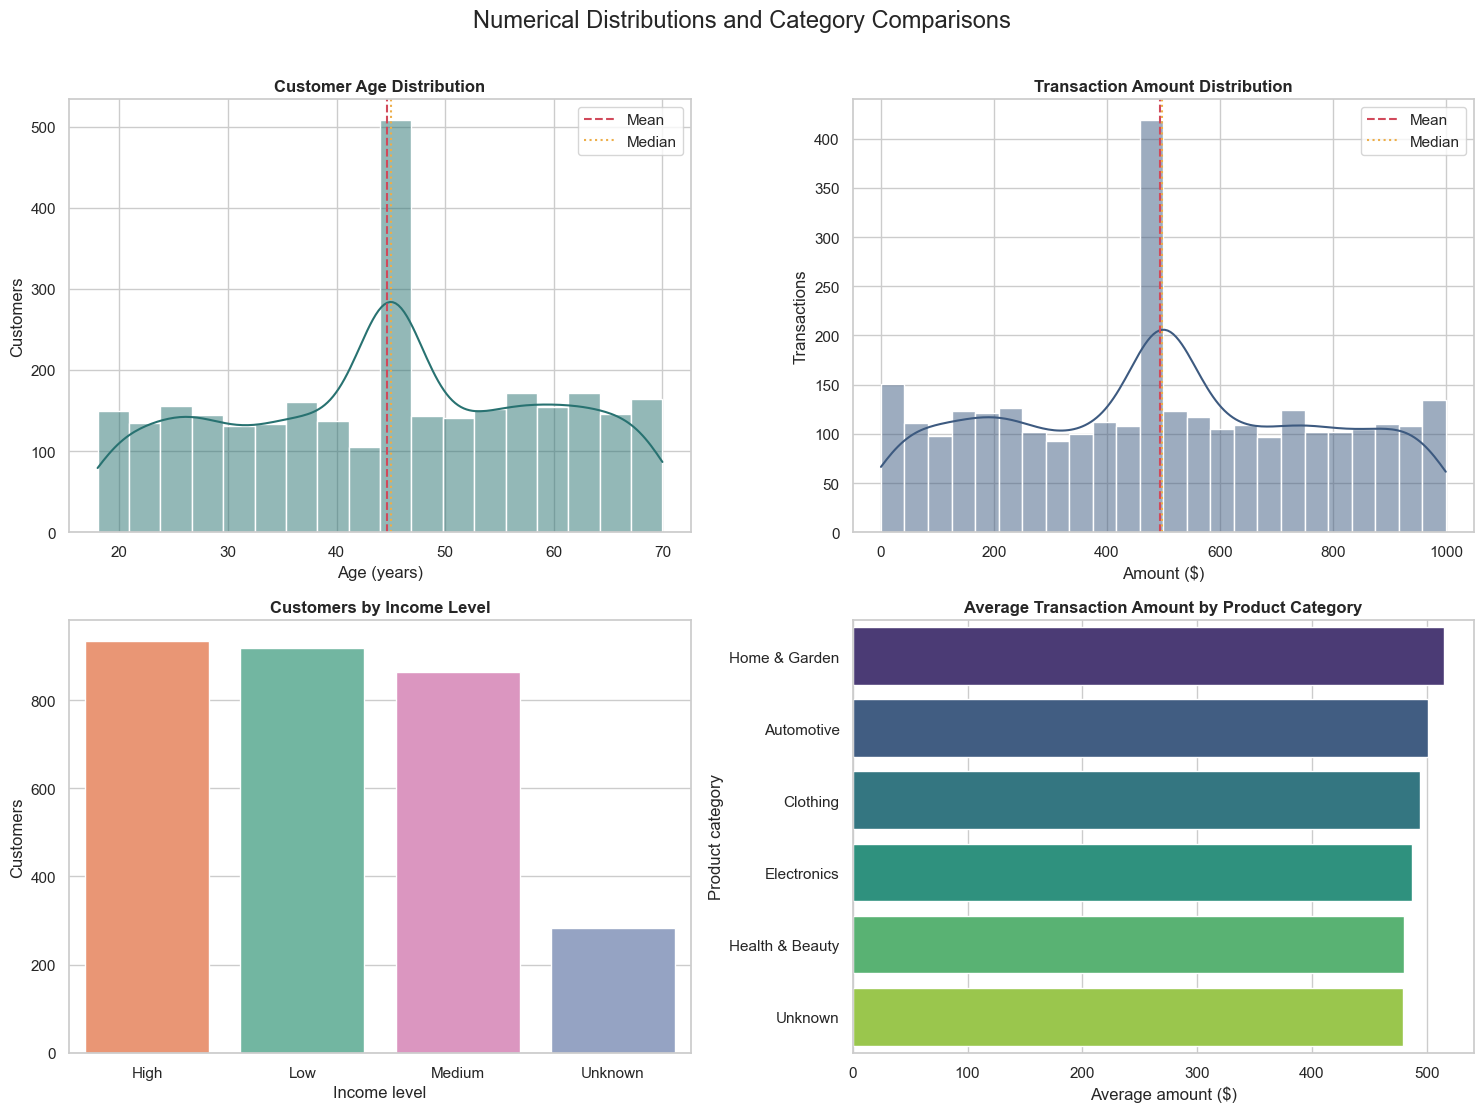

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.histplot(segments_eda, x="Age", bins=18, kde=True, color="#287271", ax=axes[0, 0])
axes[0, 0].axvline(segments_eda["Age"].mean(), color="#D1495B", linestyle="--", label="Mean")
axes[0, 0].axvline(segments_eda["Age"].median(), color="#EDAE49", linestyle=":", label="Median")
axes[0, 0].set(title="Customer Age Distribution", xlabel="Age (years)", ylabel="Customers")
axes[0, 0].legend()

sns.histplot(transactions_eda, x="Amount", bins=24, kde=True, color="#3D5A80", ax=axes[0, 1])
axes[0, 1].axvline(transactions_eda["Amount"].mean(), color="#D1495B", linestyle="--", label="Mean")
axes[0, 1].axvline(transactions_eda["Amount"].median(), color="#EDAE49", linestyle=":", label="Median")
axes[0, 1].set(title="Transaction Amount Distribution", xlabel="Amount ($)", ylabel="Transactions")
axes[0, 1].legend()

income_order = segments_eda["IncomeLevel"].value_counts().index
sns.countplot(data=segments_eda, x="IncomeLevel", order=income_order, hue="IncomeLevel", palette="Set2", legend=False, ax=axes[1, 0])
axes[1, 0].set(title="Customers by Income Level", xlabel="Income level", ylabel="Customers")

category_means = transactions_eda.groupby("ProductCategory", as_index=False)["Amount"].mean().sort_values("Amount", ascending=False)
sns.barplot(data=category_means, x="Amount", y="ProductCategory", hue="ProductCategory", palette="viridis", legend=False, ax=axes[1, 1])
axes[1, 1].set(title="Average Transaction Amount by Product Category", xlabel="Average amount ($)", ylabel="Product category")

fig.suptitle("Numerical Distributions and Category Comparisons", fontsize=17, y=1.01)
plt.tight_layout()
plt.show()

### Interpretation: Distributions and Categories
- **Age:** Mean (44.68) and median (45.00) are nearly identical, so there is little overall skew. The sharp spike at age 45 is a median-imputation artifact, not a naturally dominant age group.
- **Transaction amount:** The mean ($494.01) and median ($498.08) are also close. The large standard deviation ($279.37) shows substantial variation in purchase size. The spike near $498.08 likewise reflects median imputation and should be documented for future modeling.
- **Income balance:** High, Low, and Medium income groups are similar in size. The `Unknown` group is smaller but still meaningful and should be retained or explicitly encoded in future models.
- **Product comparison:** Category frequencies and average transaction amounts are relatively balanced; no single product category overwhelmingly dominates. This reduces the immediate risk of category-frequency bias in a predictive model.

## Relationships Between Variables
Transactions and social interactions are aggregated by `CustomerID` before merging with demographics. This avoids assuming that row positions across separate files refer to the same customer.

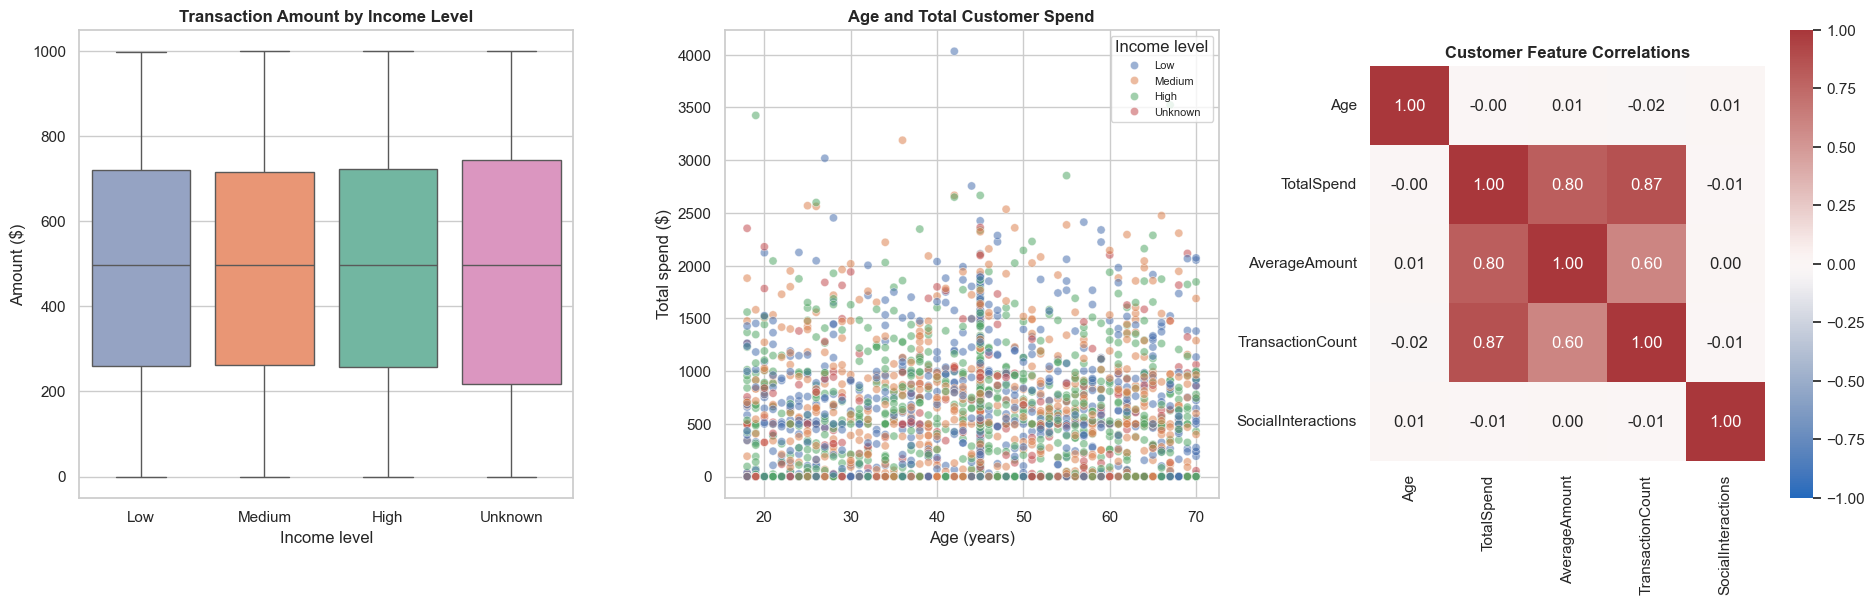

Matched transaction records: 3,000
Age-amount correlation after CustomerID join: 0.030


,count,mean,median
IncomeLevel,,,
High,949,493.03,498.08
Low,901,496.00,498.08
Medium,885,492.68,498.08
Unknown,265,495.21,498.08


In [24]:
transaction_features = transactions_eda.groupby("CustomerID").agg(
    TotalSpend=("Amount", "sum"),
    AverageAmount=("Amount", "mean"),
    TransactionCount=("TransactionID", "count"),
).reset_index()

social_features = social_eda.groupby("CustomerID").agg(
    SocialInteractions=("InteractionID", "count"),
).reset_index()

customer_features = (
    segments_eda[["CustomerID", "Age", "Gender", "IncomeLevel"]]
    .merge(transaction_features, on="CustomerID", how="left")
    .merge(social_features, on="CustomerID", how="left")
)
feature_columns = ["TotalSpend", "AverageAmount", "TransactionCount", "SocialInteractions"]
customer_features[feature_columns] = customer_features[feature_columns].fillna(0)

transaction_demographics = transactions_eda.merge(
    segments_eda[["CustomerID", "Age", "IncomeLevel"]],
    on="CustomerID",
    how="inner",
)

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

income_order = ["Low", "Medium", "High", "Unknown"]
sns.boxplot(data=transaction_demographics, x="IncomeLevel", y="Amount", order=income_order, hue="IncomeLevel", palette="Set2", legend=False, ax=axes[0])
axes[0].set(title="Transaction Amount by Income Level", xlabel="Income level", ylabel="Amount ($)")

sns.scatterplot(data=customer_features, x="Age", y="TotalSpend", hue="IncomeLevel", hue_order=income_order, alpha=0.55, s=35, ax=axes[1])
axes[1].set(title="Age and Total Customer Spend", xlabel="Age (years)", ylabel="Total spend ($)")
axes[1].legend(title="Income level", fontsize=8)

correlation_columns = ["Age", "TotalSpend", "AverageAmount", "TransactionCount", "SocialInteractions"]
correlation_matrix = customer_features[correlation_columns].corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, ax=axes[2])
axes[2].set_title("Customer Feature Correlations")

plt.tight_layout()
plt.show()

print(f"Matched transaction records: {len(transaction_demographics):,}")
print(f"Age-amount correlation after CustomerID join: {transaction_demographics['Age'].corr(transaction_demographics['Amount']):.3f}")
display(transaction_demographics.groupby("IncomeLevel")["Amount"].agg(["count", "mean", "median"]).round(2))

### Interpretation: Relationships
- **Age and spending:** The joined age-amount correlation is 0.03, indicating no meaningful linear relationship in this sample. Age alone is therefore unlikely to be a strong spending predictor.
- **Income and transaction amount:** Mean amounts are tightly grouped (about $493–$496) and all income groups have the same median ($498.08). Income level does not visibly separate purchase size.
- **Customer behavior features:** `TotalSpend` correlates strongly with `TransactionCount` (0.87) and `AverageAmount` (0.80), partly because total spend is mathematically built from those variables. Including all three in a linear model may introduce multicollinearity.
- **Social activity:** `SocialInteractions` has near-zero correlation with the spending features in this sample, so simple interaction volume does not explain purchase behavior without richer timing, platform, or sentiment features.
- **Machine-learning relevance:** Engineered behavioral features are preferable to raw IDs. Categorical variables require encoding, and `Unknown` should remain distinguishable from observed levels.

## Time Trends and Social Media Patterns
Monthly aggregation reveals whether transaction volume, average purchase size, and social activity show sustained trends or isolated peaks.

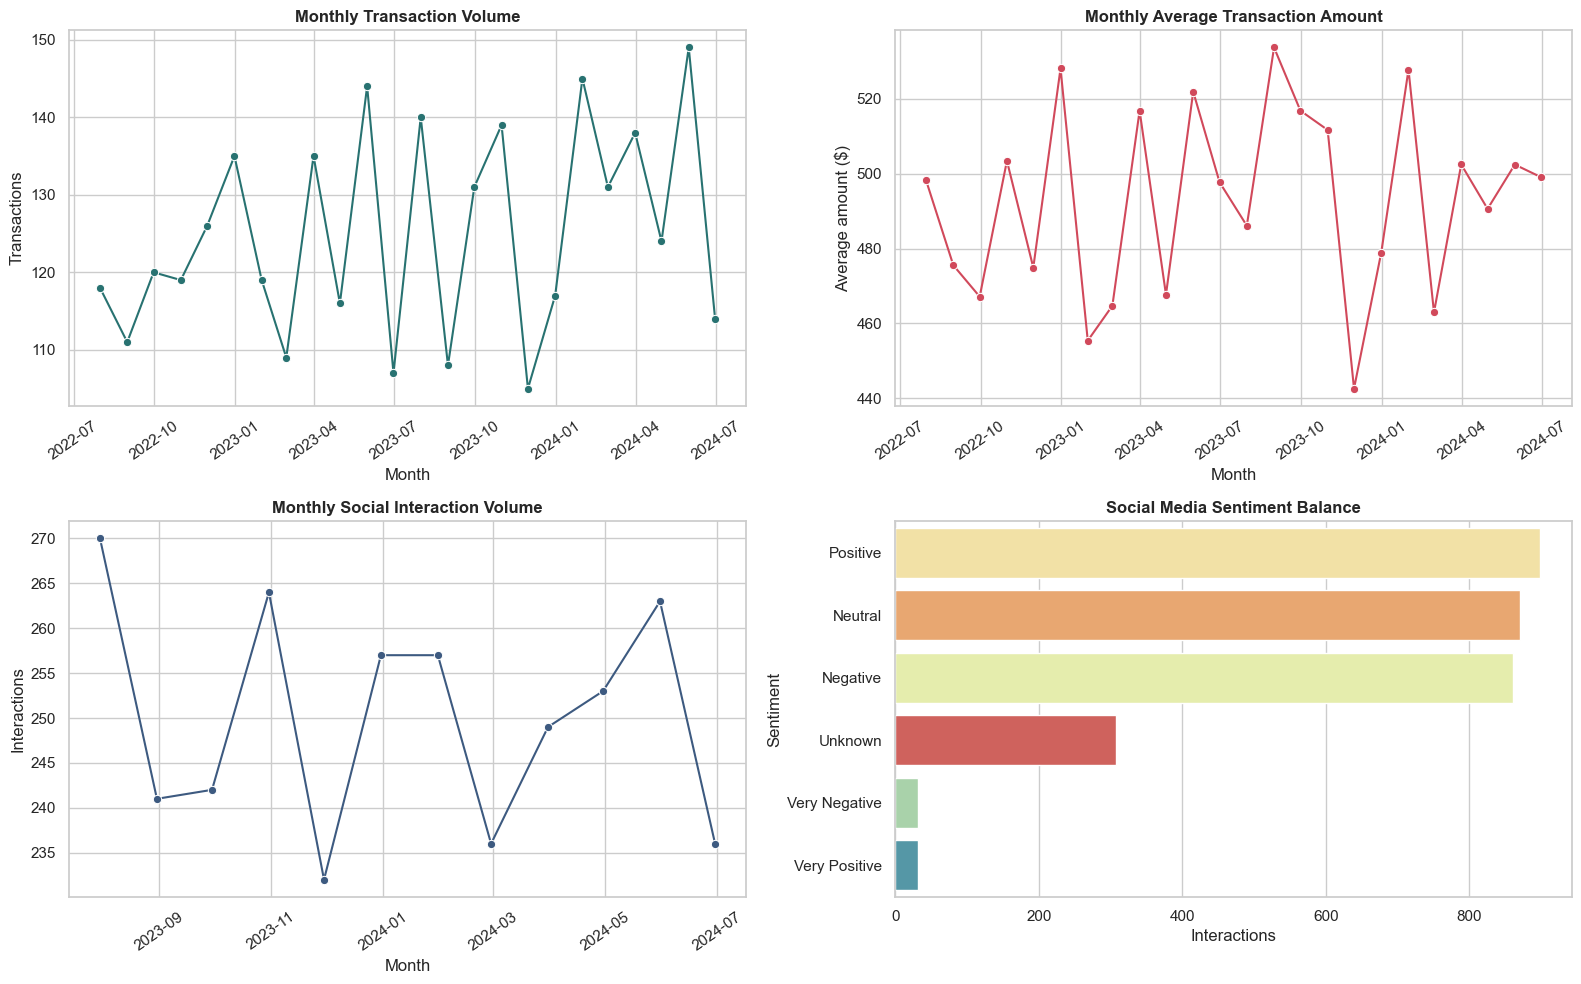

Peak transaction volume: May 2024 (149)
Highest monthly average amount: August 2023 ($533.64)
Peak social activity: July 2023 (270)


In [25]:
monthly_transactions = (
    transactions_eda.set_index("TransactionDate")
    .resample("ME")
    .agg(TransactionCount=("TransactionID", "count"), AverageAmount=("Amount", "mean"))
)
monthly_social = (
    social_eda.set_index("InteractionDate")
    .resample("ME")
    .agg(InteractionCount=("InteractionID", "count"))
)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.lineplot(data=monthly_transactions, x=monthly_transactions.index, y="TransactionCount", marker="o", color="#287271", ax=axes[0, 0])
axes[0, 0].set(title="Monthly Transaction Volume", xlabel="Month", ylabel="Transactions")

sns.lineplot(data=monthly_transactions, x=monthly_transactions.index, y="AverageAmount", marker="o", color="#D1495B", ax=axes[0, 1])
axes[0, 1].set(title="Monthly Average Transaction Amount", xlabel="Month", ylabel="Average amount ($)")

sns.lineplot(data=monthly_social, x=monthly_social.index, y="InteractionCount", marker="o", color="#3D5A80", ax=axes[1, 0])
axes[1, 0].set(title="Monthly Social Interaction Volume", xlabel="Month", ylabel="Interactions")

sentiment_order = social_eda["Sentiment"].value_counts().index
sns.countplot(data=social_eda, y="Sentiment", order=sentiment_order, hue="Sentiment", palette="Spectral", legend=False, ax=axes[1, 1])
axes[1, 1].set(title="Social Media Sentiment Balance", xlabel="Interactions", ylabel="Sentiment")

for axis in axes.flat[:3]:
    axis.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

peak_volume_month = monthly_transactions["TransactionCount"].idxmax()
peak_average_month = monthly_transactions["AverageAmount"].idxmax()
peak_social_month = monthly_social["InteractionCount"].idxmax()
print(f"Peak transaction volume: {peak_volume_month:%B %Y} ({monthly_transactions.loc[peak_volume_month, 'TransactionCount']:.0f})")
print(f"Highest monthly average amount: {peak_average_month:%B %Y} (${monthly_transactions.loc[peak_average_month, 'AverageAmount']:,.2f})")
print(f"Peak social activity: {peak_social_month:%B %Y} ({monthly_social.loc[peak_social_month, 'InteractionCount']:.0f})")

### Interpretation: Trends and Imbalances
- **Transaction volume:** Monthly counts fluctuate, with the highest volume in May 2024 (149 transactions). The line plot should be treated as variation over time rather than proof of seasonality because only two years are available.
- **Purchase value:** August 2023 has the highest monthly average transaction amount ($533.64), but nearby months remain in a similar broad range. There is no obvious sustained upward or downward spending trend.
- **Sentiment:** Positive, Neutral, and Negative interactions are similarly common. `Very Positive` and `Very Negative` are rare, creating a severe class imbalance if detailed sentiment becomes a prediction target.
- **Data quality and modeling:** The sizable `Unknown` sentiment class should not be silently merged with Neutral. For classification, stratified splitting, class weights, or carefully justified category consolidation may be needed.

## Outliers and Unusual Observations
Box plots and the 1.5 × IQR rule provide a consistent way to flag potential outliers without assuming a normal distribution.

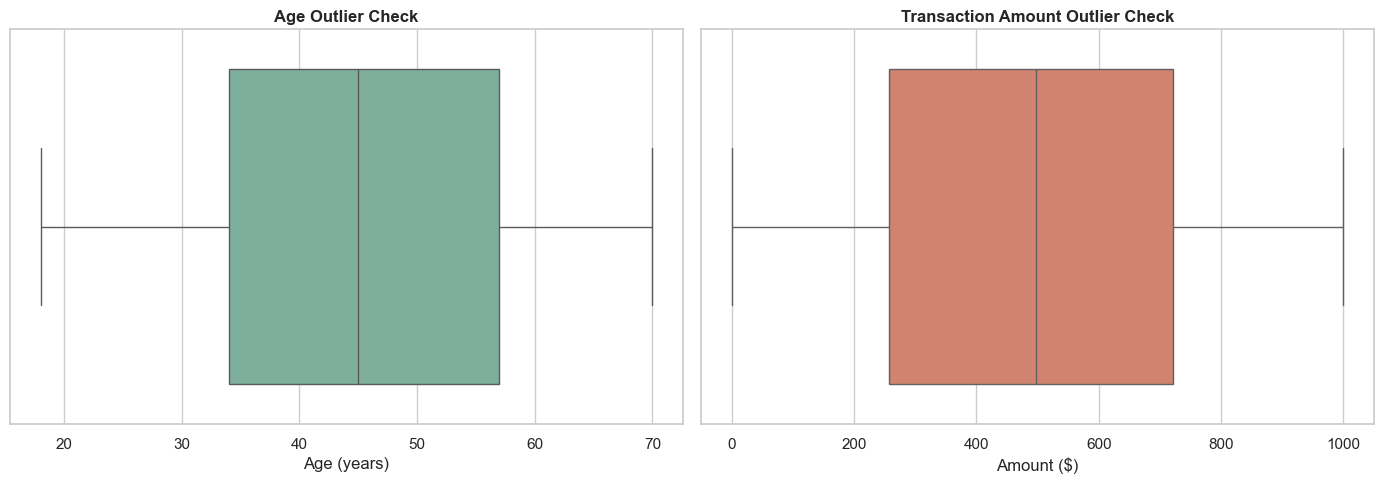

,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers
Customer Age,34.00,57.00,23.00,-0.50,91.50,0.0
Transaction Amount,257.47,721.66,464.19,-438.82,1417.96,0.0


Zero-value transactions retained after cleaning: 58


In [7]:
def iqr_outlier_summary(series):
    q1, q3 = np.percentile(series, [25, 75])
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = ((series < lower_bound) | (series > upper_bound)).sum()
    return {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outliers": int(outlier_count),
    }

outlier_summary = pd.DataFrame({
    "Customer Age": iqr_outlier_summary(segments_eda["Age"]),
    "Transaction Amount": iqr_outlier_summary(transactions_eda["Amount"]),
}).T

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=segments_eda["Age"], color="#75B79E", ax=axes[0])
axes[0].set(title="Age Outlier Check", xlabel="Age (years)")
sns.boxplot(x=transactions_eda["Amount"], color="#E07A5F", ax=axes[1])
axes[1].set(title="Transaction Amount Outlier Check", xlabel="Amount ($)")
plt.tight_layout()
plt.show()

display(outlier_summary.round(2))
print(f"Zero-value transactions retained after cleaning: {(transactions_eda['Amount'] == 0).sum():,}")

### Interpretation: Outliers and Next Steps
- The IQR rule flags **no formal outliers** for cleaned age or transaction amount. The original impossible ages and negative amounts were therefore handled successfully during preprocessing.
- There are **58 zero-dollar transactions** retained after converting `Free` to zero. They are valid within the cleaned range but remain unusual; a future model should use an `IsFreeTransaction` indicator rather than treating zero only as a continuous amount.
- Broad transaction variability is genuine distribution spread, not necessarily erroneous data. Scaling numerical features may help distance-based and gradient-based models, but records should not be removed solely for being near the valid minimum or maximum.
- Time-based prediction should use chronological train/test splits to avoid leakage. Customer-level prediction should split by `CustomerID` so records from the same customer do not appear in both training and testing data.